In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#loading dataset
data_path = "../dataset/ml-1m"

ratings = pd.read_csv(
    os.path.join(data_path, "ratings.dat"),
    sep="::",
    engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

movies = pd.read_csv(
    os.path.join(data_path, "movies.dat"),
    sep="::",
    engine="python",
    encoding="ISO-8859-1",
    names=["movie_id", "title", "genres"]
)

users = pd.read_csv(
    os.path.join(data_path, "users.dat"),
    sep="::",
    engine="python",
    names=["user_id", "gender", "age", "occupation", "zip_code"]
)

print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Users:", users.shape)

Ratings: (1000209, 4)
Movies: (3883, 3)
Users: (6040, 5)


In [3]:
display(ratings.head())
display(movies.head())
display(users.head())

,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [4]:
print("RATINGS")
display(ratings.head())

print("MOVIES")
display(movies.head())

RATINGS


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


MOVIES


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
display(ratings.head())

,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [6]:
print("RATINGS INFO")
ratings.info()

print("\nMOVIES INFO")
movies.info()

print("\nUSERS INFO")
users.info()

RATINGS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  int64
 1   movie_id   1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB

MOVIES INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   movie_id  3883 non-null   int64 
 1   title     3883 non-null   object
 2   genres    3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB

USERS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     6040 non-null   int64

In [7]:
#checking missing value explicitly
print("Ratings missing values:\n", ratings.isnull().sum())
print("\nMovies missing values:\n", movies.isnull().sum())
print("\nUsers missing values:\n", users.isnull().sum())

Ratings missing values:
 user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Movies missing values:
 movie_id    0
title       0
genres      0
dtype: int64

Users missing values:
 user_id       0
gender        0
age           0
occupation    0
zip_code      0
dtype: int64


rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

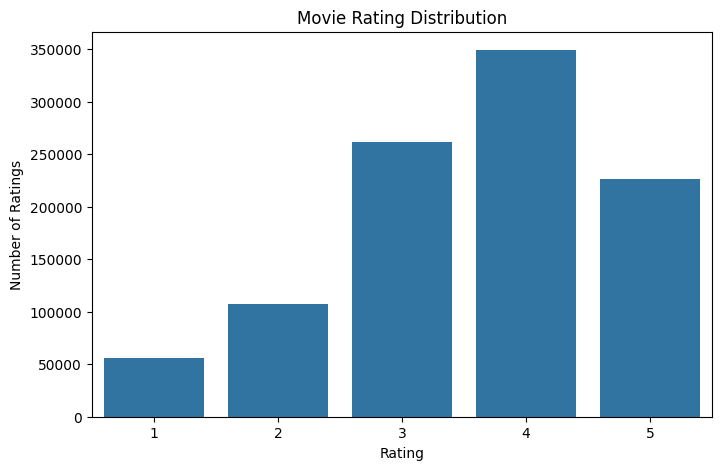

In [9]:
#visulatization
rating_counts = ratings["rating"].value_counts().sort_index()

display(rating_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values)
plt.title("Movie Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

In [10]:
#user and movie activity
user_activity = ratings.groupby("user_id")["rating"].count()
movie_popularity = ratings.groupby("movie_id")["rating"].count()

print("User activity:")
display(user_activity.describe())

print("\nMovie popularity:")
display(movie_popularity.describe())

User activity:


count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
Name: rating, dtype: float64


Movie popularity:


count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
Name: rating, dtype: float64

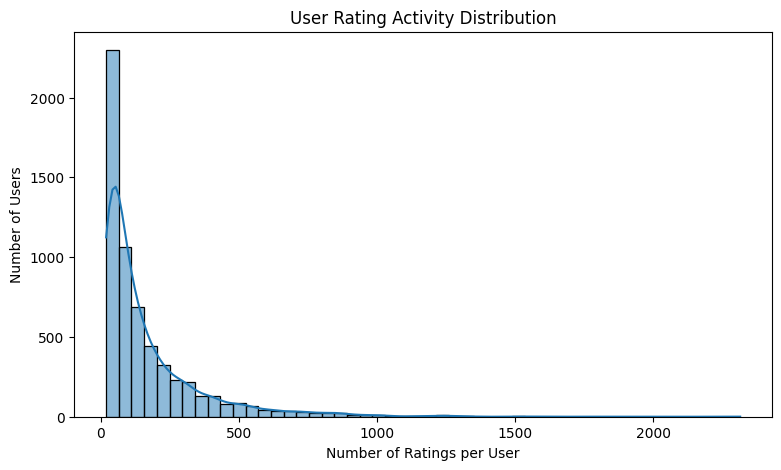

In [11]:
#visualization of user activty 
plt.figure(figsize=(9, 5))
sns.histplot(user_activity, bins=50, kde=True)

plt.title("User Rating Activity Distribution")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")
plt.show()

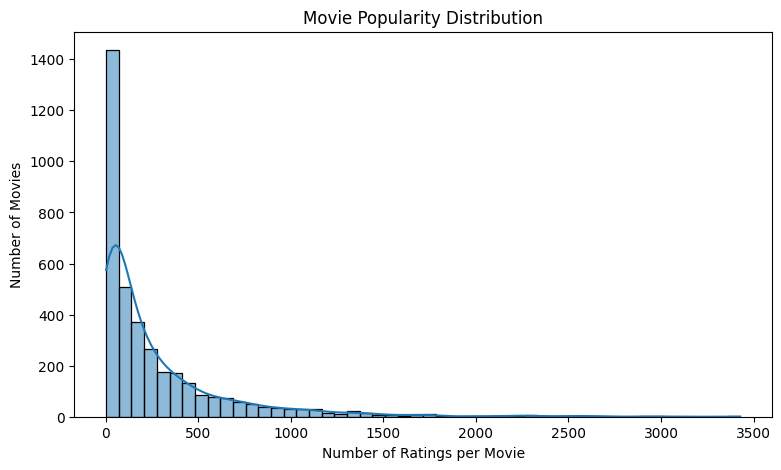

In [12]:
#movie popularity distribution
plt.figure(figsize=(9, 5))
sns.histplot(movie_popularity, bins=50, kde=True)

plt.title("Movie Popularity Distribution")
plt.xlabel("Number of Ratings per Movie")
plt.ylabel("Number of Movies")
plt.show()


genres
Drama          1603
Comedy         1200
Action          503
Thriller        492
Romance         471
Horror          343
Adventure       283
Sci-Fi          276
Children's      251
Crime           211
War             143
Documentary     127
Musical         114
Mystery         106
Animation       105
Fantasy          68
Western          68
Film-Noir        44
Name: count, dtype: int64

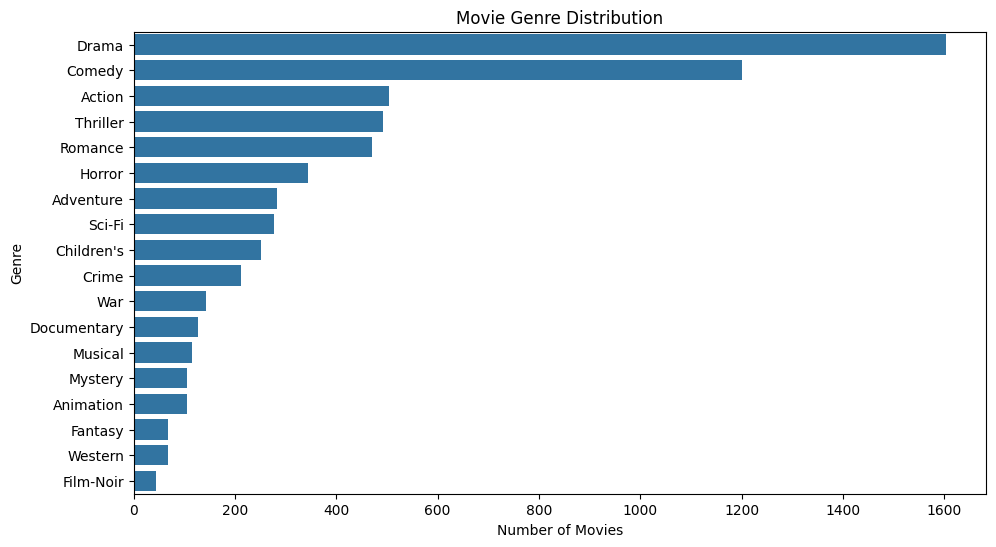

In [13]:
#genre distribution
genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

display(genre_counts)

plt.figure(figsize=(11, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)

plt.title("Movie Genre Distribution")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.show()

gender
M    4331
F    1709
Name: count, dtype: int64

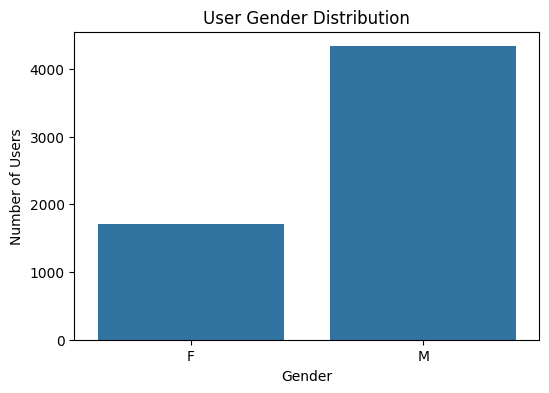

In [14]:
#user demographics 
gender_counts = users["gender"].value_counts()

display(gender_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=users, x="gender")

plt.title("User Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Users")
plt.show()

age
1      222
18    1103
25    2096
35    1193
45     550
50     496
56     380
Name: count, dtype: int64

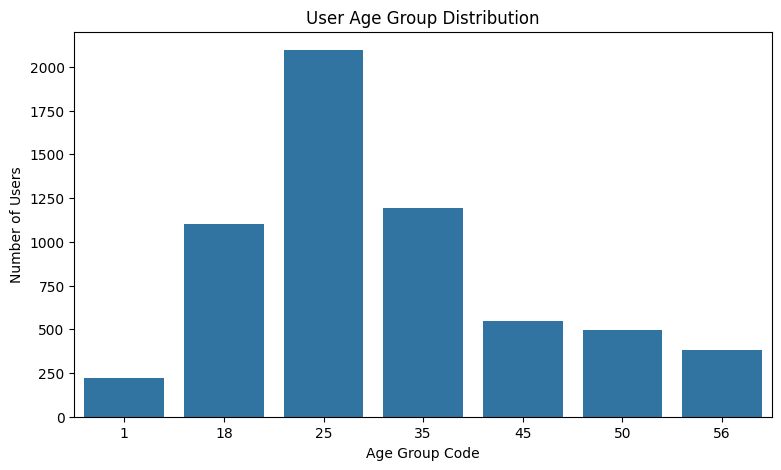

In [15]:
#age distribution 
age_counts = users["age"].value_counts().sort_index()

display(age_counts)

plt.figure(figsize=(9, 5))
sns.barplot(x=age_counts.index, y=age_counts.values)

plt.title("User Age Group Distribution")
plt.xlabel("Age Group Code")
plt.ylabel("Number of Users")
plt.show()

occupation
0     711
1     528
2     267
3     173
4     759
5     112
6     236
7     679
8      17
9      92
10    195
11    129
12    388
13    142
14    302
15    144
16    241
17    502
18     70
19     72
20    281
Name: count, dtype: int64

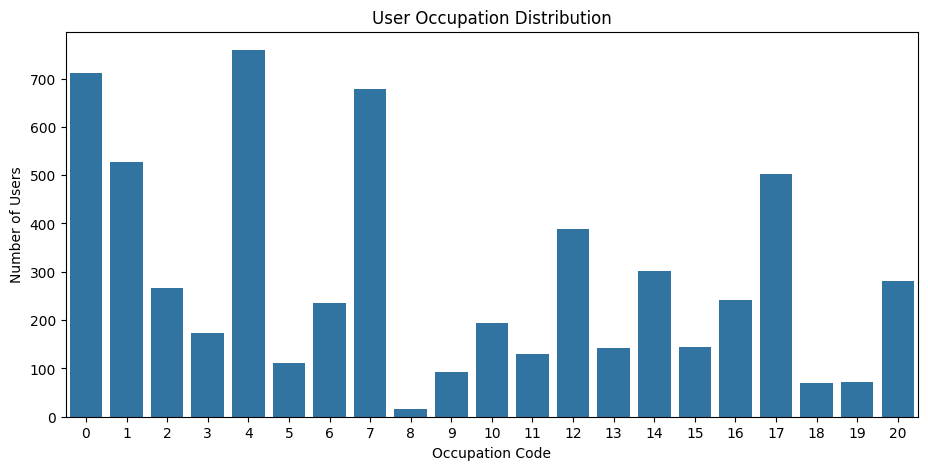

In [16]:
#occupation distribution
occupation_counts = users["occupation"].value_counts().sort_index()

display(occupation_counts)

plt.figure(figsize=(11, 5))
sns.barplot(x=occupation_counts.index, y=occupation_counts.values)

plt.title("User Occupation Distribution")
plt.xlabel("Occupation Code")
plt.ylabel("Number of Users")
plt.show()

In [17]:
#checking rating timestamp
ratings["datetime"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s"
)

print("First rating date:", ratings["datetime"].min())
print("Last rating date:", ratings["datetime"].max())

ratings["year"] = ratings["datetime"].dt.year

display(ratings["year"].value_counts().sort_index())

First rating date: 2000-04-25 23:05:32
Last rating date: 2003-02-28 17:49:50


year
2000    904757
2001     68058
2002     24046
2003      3348
Name: count, dtype: int64

In [18]:
#duplicate data 
duplicate_count = ratings.duplicated(
    subset=["user_id", "movie_id"]
).sum()

print("Duplicate user-movie interactions:", duplicate_count)

Duplicate user-movie interactions: 0


In [19]:
print("Unique ratings:", sorted(ratings["rating"].unique()))

print("\nMinimum rating:", ratings["rating"].min())
print("Maximum rating:", ratings["rating"].max())

Unique ratings: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Minimum rating: 1
Maximum rating: 5
